<a href="https://colab.research.google.com/github/edvalenciah69/portafolio/blob/main/clase_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# El precio de la luz (gemelo)

**Taller en Ciencia de Datos y Aprendizaje Automático** · Especialización en Estadística · UNAL Manizales · 2026-II
Profesor: Carlos Manuel Orrego Franco

Este cuaderno lo resuelve cada uno, de forma individual. Es el gemelo de *El sancocho*: la misma técnica en otro mundo. Termina como *El IPC del sancocho*, con su propio post.

| Ficha | |
|---|---|
| **Objetivo pedagógico** | Repetir por cuenta propia el camino de la clase: formular, limpiar, explorar, comparar modelos contra una línea base con validación temporal, decidir y contar el resultado en un post. |
| **Enfoque** | Ciencia de Datos. |
| **Resultados de aprendizaje** | 1 (formular), 2 (seleccionar y preparar datos), 3 (flujo reproducible), 4 (implementar y evaluar) y 5 (comunicar). |
| **Uso de IA** | Pueden pedirle a Claude que explique una celda, que les ayude a llenar un hueco o que interprete un error. Deben poder explicar sin ayuda la regla con que se escogió la versión del precio, por qué los tramos son temporales, por qué el ganador se escoge en validación y qué significa su MAPE. |
| **Entregable** | El cuaderno corrido en su portafolio de GitHub, con las predicciones, la decisión en tres frases y la bitácora llenas, y sus dos láminas para LinkedIn. |

**Cómo se trabaja.** El código está escrito casi todo. Donde vean `____` falta una pieza, y el comentario de al lado dice qué va. Lean la celda entera antes de llenar. Si una celda falla, lean el error antes de pedir ayuda.

In [1]:
# Celda de arranque. No hay que cambiarle nada: trae las herramientas del curso.
import pathlib, subprocess, sys
raiz = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path.cwd() / "taller-cd-ml-2026-2"] if (p / "taller" / "datos.py").exists()), None)
if raiz is None:
    subprocess.run(["git", "clone", "-q", "https://github.com/cmorregof/taller-cd-ml-2026-2.git"], check=True)
    raiz = pathlib.Path("taller-cd-ml-2026-2")
sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from taller import descargar, procedencia

PALETA = ["#1D4E89", "#D7263D", "#1B998B", "#6C4AB6", "#5BC0EB", "#F49097", "#9AA5B1"]      # colores del curso
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=PALETA), "axes.titleweight": "bold", "figure.dpi": 110})
print("Herramientas listas.")

Herramientas listas.


## 1. Formulación

En Colombia la energía se compra y se vende cada hora en un mercado que administra XM. El precio de ese mercado se llama **precio de bolsa** y se mide en pesos por kilovatio hora. La explicación que uno oye siempre es que el precio sube cuando los embalses bajan, porque hay que prender plantas térmicas, que son más caras. Hoy vamos a ver cuánto de esa explicación aguanta el dato.

Imagínense una empresa mediana de Manizales que gasta mucha energía. Puede comprarla al precio de bolsa, que cambia todos los días, o firmar un precio fijo. Su gerente necesita tres respuestas:

1. **Predecir.** ¿Cuál será el precio de bolsa promedio de mañana? ¿Y el de dentro de siete días?
2. **Explicar.** ¿Cuánto del precio se entiende mirando el nivel de los embalses?
3. **Decidir.** Si le ofrecen un precio fijo, ¿desde qué valor le conviene firmar?

**La métrica** es la misma de la clase: el MAPE del pronóstico, primero a un día y después a siete.

### Predicción escrita

Escriban su apuesta antes de correr nada.

- ¿Cuánto vale hoy un kilovatio hora en bolsa, en pesos? **Mi apuesta:**
- ¿Qué tan lejos queda el precio de mañana del precio de hoy, en porcentaje? ¿Y el de dentro de siete días? **Mi apuesta:**
- Cuando los embalses están llenos, ¿el precio es alto o bajo? **Mi apuesta:**

#1.
500 pesos
#2.
1%, y en 7 dias el mismo 1%
#3.
bajo dado que se encuentra mas oferta energetica que demanda (aprpximadamente ya que depende del embalse)

## 2. Datos

Pedimos dos tablas a XM: el precio de bolsa hora por hora y la energía guardada en cada embalse día por día, de enero de 2023 a octubre de 2026. **En Colab la descarga tarda unos doce minutos**, porque XM entrega un mes por consulta. Córranla apenas empiecen y lean la sección mientras termina.

In [2]:
precio_crudo = descargar("xm_precio")
embalses_crudo = descargar("xm_embalses")
from taller.presentacion import ficha_del_dato, RegistroDeLimpieza, nube_3d
display(ficha_del_dato(precio_crudo, "Precio de bolsa, tal como lo entrega XM"))
display(ficha_del_dato(embalses_crudo, "Embalses, tal como los entrega XM"))
precio_crudo.head(8)

[xm_precio] Descargo de la fuente oficial: XM, SiMEM, conjunto EC6945.
   SiMEM, conjunto EC6945: 46 meses…
[xm_precio] Listo: 667.128 filas.
[xm_embalses] Descargo de la fuente oficial: XM, SiMEM, conjunto c51127.
   SiMEM, conjunto c51127: 46 meses…
[xm_embalses] Listo: 36.804 filas.


,tipo,sin dato (%),valores distintos,ejemplo
columna,,,,
FechaHora,object,0.0,33600,2023-01-01 00:00:00
CodigoVariable,object,0.0,3,PB_Int
Version,object,0.0,10,TX1
Valor,float64,0.0,87634,509.5


,tipo,sin dato (%),valores distintos,ejemplo
columna,,,,
Fecha,object,0.0,1400,2023-01-01
CodigoEmbalse,object,0.0,29,AGREGADO_BOGOTA
RegionHidrologica,object,0.0,8,Centro
VolumenUtilDiarioEnergia,float64,0.0,31383,2540271200.0
CapacidadUtilEnergia,float64,0.0,230,4082390003.0


columna,FechaHora,CodigoVariable,Version,Valor
0,2023-01-01 00:00:00,PB_Int,TX1,509.5000
1,2023-01-01 00:00:00,PB_Int,TX2,509.5000
2,2023-01-01 00:00:00,PB_Int,TX3,510.5627
3,2023-01-01 00:00:00,PB_Int,TX4,510.5627
4,2023-01-01 00:00:00,PB_Int,TX5,510.5842
5,2023-01-01 00:00:00,PB_Int,TX6,510.5842
6,2023-01-01 00:00:00,PB_Int,TXF,510.5207
7,2023-01-01 00:00:00,PB_Int,TXR,510.5208


### 2.1 La primera trampa: cada hora aparece muchas veces

Miren la tabla de arriba. La misma hora sale repetida. Averigüemos por qué.

In [3]:
print("Filas:", len(precio_crudo), "| Horas distintas:", precio_crudo["FechaHora"].nunique())
print(precio_crudo.groupby(["CodigoVariable", "Version"]).size().unstack())

Filas: 667128 | Horas distintas: 33600
Version           TX1    TX2    TX3    TX4    TX5   TX6   TX7  TX8    TXF  \
CodigoVariable                                                              
PB_Int          33576  31944  30648  28464  18192  8712  2928  720  33600   
PB_Nal          33576  31944  30648  28464  18192  8712  2928  720  33600   
PB_Tie          33576  31920  30648  28464  18192  8712  2928  720  33600   

Version           TXR  
CodigoVariable         
PB_Int          33600  
PB_Nal          33600  
PB_Tie          33600  


Hay tres variables y hasta diez versiones:

- `PB_Nal` es el precio de bolsa nacional. `PB_Int` y `PB_Tie` son precios para intercambios con otros países. A la empresa le interesa el nacional.
- XM liquida cada hora varias veces. Las versiones numeradas van de `TX1` a `TX8`: casi todas las horas tienen `TX1` y muy pocas llegan a `TX8`, así que el número indica cuántas veces se ha vuelto a liquidar esa hora. Además están `TXF` y `TXR`, que existen para todas las horas.

Si promediaran la tabla tal como viene, mezclarían precios internacionales con nacionales y contarían la misma hora varias veces. Además, las versiones no siempre coinciden. Miren un día concreto:

In [4]:
un_dia = precio_crudo[(precio_crudo["CodigoVariable"] == "PB_Nal") & precio_crudo["FechaHora"].str.startswith("2024-09-30")]
print(un_dia.groupby("Version")["Valor"].mean().round(0))

Version
TX1    7233.0
TX3    2499.0
TX4    2499.0
TX5    2499.0
TX6    2499.0
TX7    2499.0
TX8    2499.0
TXF    7235.0
TXR    7235.0
Name: Valor, dtype: float64


El mismo día vale más de 7.000 pesos según unas versiones y menos de 2.500 según otras. Quien escoja otra versión estará modelando otro precio.

**Regla que vamos a usar:** nos quedamos con el precio nacional y, para cada hora, con la liquidación numerada más reciente que exista (`TX8` si la hay, si no `TX7`, y así hasta `TX1`). Solo si una hora no tiene ninguna numerada usamos `TXF`. La razón es que una liquidación posterior corrige a las anteriores.

Esta regla es una decisión de modelación que tomé mirando el dato, sin tener a la mano la definición oficial de cada sigla. Anótenla en la bitácora y, en la sección de riesgos, digan qué habría que consultarle a XM.

In [6]:
nacional = precio_crudo[precio_crudo["CodigoVariable"] == "PB_Nal"].copy()   # HUECO 1: el código del precio nacional, entre comillas

preferencia = ["TX8", "TX7", "TX6", "TX5", "TX4", "TX3", "TX2", "TX1", "TXF", "TXR"]
nacional["orden"] = nacional["Version"].map({v: i for i, v in enumerate(preferencia)})
horario = (nacional.sort_values(["FechaHora", "orden"])
           .drop_duplicates("FechaHora", keep="first"))                       # HUECO 2: "first" o "last". ¿Cuál deja la versión preferida?

print("Horas después de limpiar:", len(horario), "| ¿Alguna hora repetida?", horario["FechaHora"].duplicated().any())
print(horario["Version"].value_counts().sort_index())

registro = RegistroDeLimpieza(len(precio_crudo))
registro.anotar("Solo el precio nacional (PB_Nal)", "salen PB_Int y PB_Tie", len(precio_crudo) - len(nacional), len(nacional))
registro.anotar("Una liquidación por hora", "queda la numerada más reciente", len(nacional) - len(horario), len(horario))
display(registro.tabla("Registro de limpieza del precio"))

Horas después de limpiar: 33600 | ¿Alguna hora repetida? False
Version
TX2     1464
TX3     3672
TX4    10272
TX5     9480
TX6     5784
TX7     2208
TX8      720
Name: count, dtype: int64


,regla,decisión,filas afectadas,filas que quedan,% del dato original
1,Solo el precio nacional (PB_Nal),salen PB_Int y PB_Tie,444.744,222.384,33.3
2,Una liquidación por hora,queda la numerada más reciente,188.784,33.600,5.0


**Compruébenlo ustedes mismos.** El número de horas después de limpiar debe ser igual al número de horas distintas que imprimieron antes. Si no coincide, revisen los huecos 1 y 2.

### 2.2 Del precio horario al precio diario

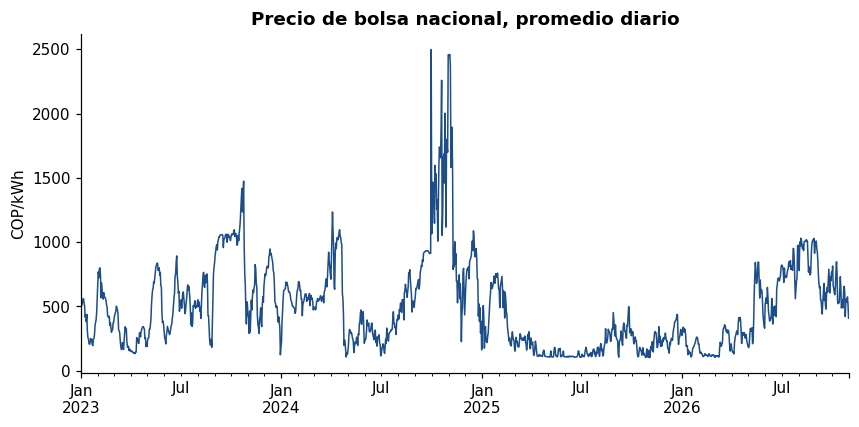

count    1400.0
mean      491.9
std       349.6
min       102.8
25%       222.3
50%       416.1
75%       680.4
max      2498.8
Name: precio, dtype: float64


In [8]:
horario["fecha"] = pd.to_datetime(horario["FechaHora"]).dt.normalize()
precio = horario.groupby("fecha")["Valor"].mean().rename("precio")           # HUECO 3: la operación que resume las 24 horas en un promedio

ax = precio.plot(color="#1D4E89", lw=1)
ax.set(title="Precio de bolsa nacional, promedio diario", xlabel="", ylabel="COP/kWh"); plt.show()
print(precio.describe().round(1))

Comparen con su primera apuesta. ¿Qué pasó entre finales de 2023 y abril de 2024? Escríbanlo en una línea: **Mi explicación:** el precio decrecio por debajo de los 500 pesos por lo que la apuesta fue errada.

### 2.3 El nivel de los embalses

La tabla trae, por embalse y por día, la energía útil guardada y la capacidad útil. El nivel agregado del país es la suma de lo guardado sobre la suma de la capacidad.

**Segunda trampa: filas que ya son sumas.** Miren los nombres de los embalses.

In [9]:
print(sorted(embalses_crudo["CodigoEmbalse"].unique()))

['AGREGADO', 'AGREGADO_BOGOTA', 'AGREGADO_SIN', 'ALTOANCH', 'BETANIA', 'CALIMA1', 'CHUZA', 'ELQUIMBO', 'ESMERALD', 'GUAVIO', 'ITUANGO', 'MIEL1', 'MIRAFLOR', 'MUNA', 'NEUSA', 'PENOL', 'PLAYAS', 'PORCE2', 'PORCE3', 'PRADO', 'PUNCHINA', 'RIOGRAN2', 'SALVAJIN', 'SANLOREN', 'SISGA', 'SOGAMOSO', 'TOMINE', 'TRONERAS', 'URRA1']


Tres nombres no son embalses. `AGREGADO_SIN` es el total del país, que XM publica desde julio de 2025. `AGREGADO_BOGOTA`, que desde enero de 2025 aparece como `AGREGADO`, es la suma de Neusa, Sisga y Tominé, que hasta junio de 2025 también vienen por separado. Si sumaran todas las filas contarían esa agua dos y hasta tres veces.

La celda siguiente quita las filas repetidas y calcula el nivel. Después lo compara con el total que publica XM, para saber si la regla quedó bien.

Diferencia máxima con el total de XM, en 488 días comparables: 0.000 puntos
1400 días, de 2023-01-01 a 2026-10-31


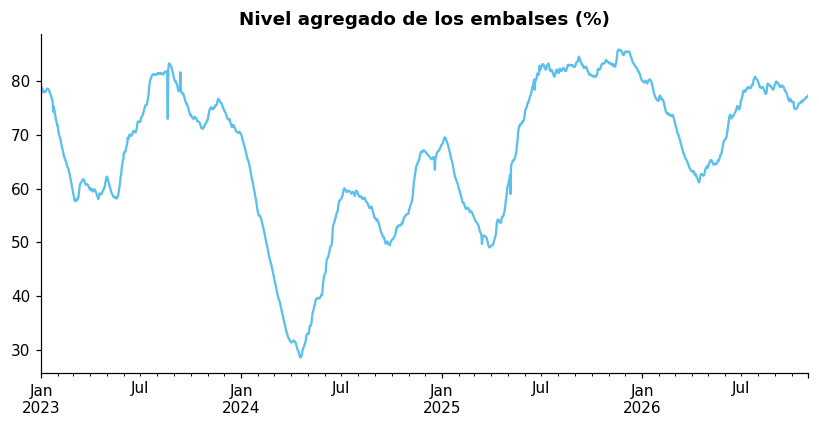

In [10]:
embalses_crudo["fecha"] = pd.to_datetime(embalses_crudo["Fecha"])
repetidas = ["AGREGADO_SIN", "NEUSA", "SISGA", "TOMINE"]
sin_repetir = embalses_crudo[~embalses_crudo["CodigoEmbalse"].isin(repetidas)]
por_dia = sin_repetir.groupby("fecha")[["VolumenUtilDiarioEnergia", "CapacidadUtilEnergia"]].sum()
embalse = (por_dia["VolumenUtilDiarioEnergia"] / por_dia["CapacidadUtilEnergia"] * 100).rename("embalse")   # HUECO 4: la columna que va en el denominador

oficial = embalses_crudo[embalses_crudo["CodigoEmbalse"] == "AGREGADO_SIN"].set_index("fecha")
oficial = oficial["VolumenUtilDiarioEnergia"] / oficial["CapacidadUtilEnergia"] * 100
diferencia = (embalse.reindex(oficial.index) - oficial).abs().max()
print(f"Diferencia máxima con el total de XM, en {len(oficial)} días comparables: {diferencia:.3f} puntos")

datos = pd.concat([precio, embalse], axis=1).dropna()
print(len(datos), "días, de", datos.index.min().date(), "a", datos.index.max().date())
datos["embalse"].plot(color="#5BC0EB"); plt.title("Nivel agregado de los embalses (%)"); plt.xlabel(""); plt.show()

### 2.4 Conocer el dato antes de modelarlo

Tres miradas rápidas: a qué horas es cara la energía, si el día de la semana importa y cómo se reparten los precios.

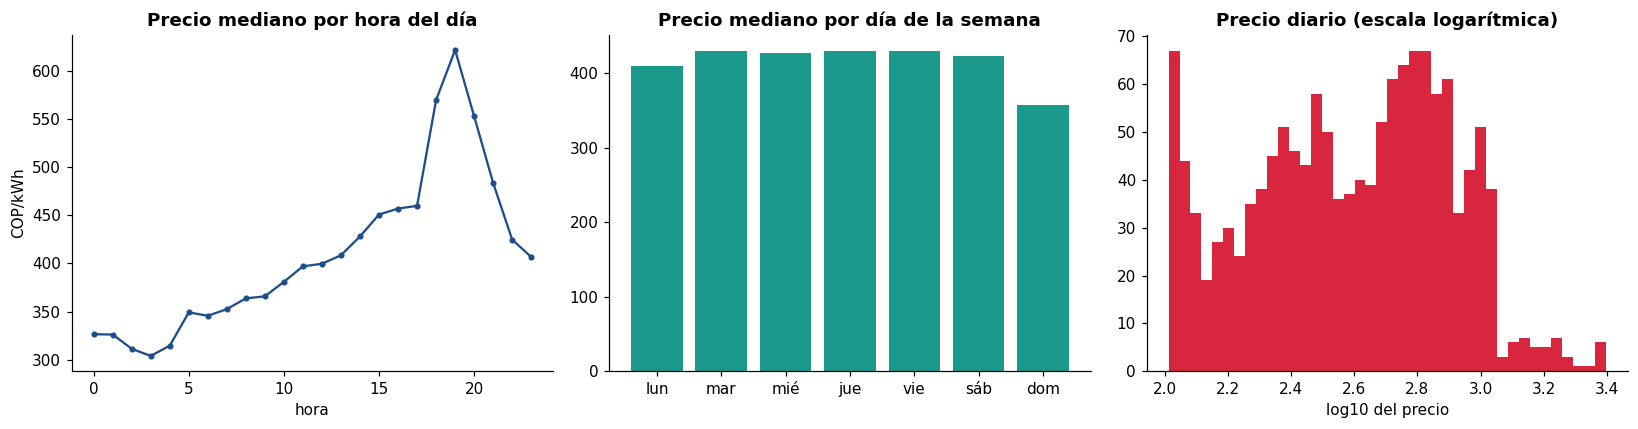

Media: 492 | Mediana: 416 | Máximo: 2499 COP/kWh


In [13]:
horario["hora"] = pd.to_datetime(horario["FechaHora"]).dt.hour
dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
horario.groupby("hora")["Valor"].median().plot(ax=ejes[0], color="#1D4E89", marker="o", ms=3)      # HUECO 5: un resumen que no se deje arrastrar por los días extremos
ejes[0].set(title="Precio mediano por hora del día", xlabel="hora", ylabel="COP/kWh")
por_dia_semana = datos["precio"].groupby(datos.index.dayofweek).median()
ejes[1].bar(dias, por_dia_semana.values, color="#1B998B"); ejes[1].set(title="Precio mediano por día de la semana")
ejes[2].hist(np.log10(datos["precio"]), bins=40, color="#D7263D")
ejes[2].set(title="Precio diario (escala logarítmica)", xlabel="log10 del precio")
plt.tight_layout(); plt.show()
print(f"Media: {datos['precio'].mean():.0f} | Mediana: {datos['precio'].median():.0f} | Máximo: {datos['precio'].max():.0f} COP/kWh")

- ¿A qué hora es más cara la energía, y por qué creen? **Mi lectura:** hay dos picos, en la mañana y la noche, a las 6 se enciende el alumbdado y las personas vuelven a sus casas del trabajo, por eso a esa hora hay un consumo aumentado
- La media y la mediana no coinciden. ¿Qué dice eso de la forma de la distribución? **Mi lectura:**
que la mediana esta un poco por debajo de la media por lo que los datos tienden a estar por encima del promedio

**Una prueba de hipótesis: ¿importa el día de la semana?** Las barras de arriba se ven distintas, pero las barras siempre se ven distintas. La prueba de Kruskal-Wallis compara los siete grupos de precios, uno por día de la semana, y contrasta

$$H_0:\ \text{los siete días tienen la misma distribución de precios}\qquad\text{contra}\qquad H_1:\ \text{al menos uno se desplaza}.$$

Usa rangos y no promedios, así que los días de precio extremo no la arrastran.

In [14]:
from scipy.stats import kruskal

grupos = [datos.loc[datos.index.dayofweek == d, "precio"] for d in range(7)]
estadistico, valor_p = kruskal(*grupos)
print(f"Estadístico H: {estadistico:.1f} | valor p: {valor_p:.4f}")
print("Mediana por día:", {dias[d]: round(float(g.median())) for d, g in enumerate(grupos)})

Estadístico H: 9.5 | valor p: 0.1480
Mediana por día: {'lun': 410, 'mar': 430, 'mié': 428, 'jue': 429, 'vie': 430, 'sáb': 422, 'dom': 358}


- Con ese valor $p$, ¿rechazan $H_0$? ¿El efecto es grande o pequeño frente a lo que cambia el precio de un mes a otro? **Mi lectura:**

## 3. Modelado

### 3.1 La línea base

Con horizonte $h$ días, dos pronósticos que no cuestan nada:

$$\hat P^{\text{ing}}_{t+h}=P_t\qquad\text{y}\qquad \hat P^{\text{sem}}_{t+h}=\frac{1}{7}\sum_{j=0}^{6}P_{t-j}.$$

El error se mide igual que en clase: $\text{MAPE}=\dfrac{100}{n}\sum_t\left|\dfrac{P_{t+h}-\hat P_{t+h}}{P_{t+h}}\right|$.

Empezamos con $h=1$: el precio de mañana. Al final del cuaderno cambiarán esa línea por $h=7$.

In [37]:
H = 1                                                   # horizonte en días. Al final lo cambiarán por 7.
tabla = pd.DataFrame({"real": datos["precio"].shift(H)})   # HUECO 6: el desplazamiento que trae el precio de dentro de H días a la fila de hoy
tabla["ingenuo"] = datos["precio"]
tabla["promedio_7"] = datos["precio"].rolling(7).mean()
tabla = tabla.dropna()

def mape(real, pronostico):
    return float((abs(real - pronostico) / real).mean() * 100)   # HUECO 7: ¿contra qué se compara el error para volverlo porcentaje?

for metodo in ["ingenuo", "promedio_7"]:
    print(f"MAPE {metodo}: {mape(tabla['real'], tabla[metodo]):.1f} %")

MAPE ingenuo: 12.2 %
MAPE promedio_7: 13.9 %


Comparen con su segunda apuesta.

### 3.2 Ocho candidatos y el mismo protocolo de la clase

Compiten las dos líneas base, el **suavizado exponencial** y cinco modelos de aprendizaje: regresión lineal, Ridge, $k$ vecinos, bosque aleatorio y *gradient boosting*. Los cinco modelos pronostican el **cambio relativo** $P_{t+h}/P_t$ y no el nivel, por la razón que vimos con el sancocho: los árboles y los vecinos no pueden pronosticar por encima de lo que ya vieron.

Esto es lo que ve cada modelo el día $t$. La función `competir` lo arma, pero ustedes deben saber leerlo:

| Variable | En palabras |
|---|---|
| `ayer` | el precio de ayer, como fracción del de hoy |
| `promedio_7`, `promedio_30` | el promedio de la última semana y del último mes, como fracción del de hoy |
| `embalse` | el nivel agregado de los embalses hoy |
| `embalse_cambio_7` | cuánto subió o bajó el embalse en la última semana |
| `dia_semana` | de 0 (lunes) a 6 (domingo) |

El suavizado exponencial lleva un nivel que se actualiza con cada dato, $\ell_t=\alpha P_t+(1-\alpha)\,\ell_{t-1}$, y lo usa como pronóstico. Con $\alpha=1$ es el ingenuo. El valor de $\alpha$ se escoge solo con el entrenamiento.

El tiempo se parte en tres tramos:

$$\underbrace{2023\ \dots\ 2024}_{\text{entrenamiento}}\ \Big|\ \underbrace{\text{ene}\ \dots\ \text{jun } 2025}_{\text{validación: se escoge}}\ \Big|\ \underbrace{\text{jul } 2025\ \dots\ \text{oct } 2026}_{\text{prueba: se reporta}}$$

**Predicción escrita:** ¿algún modelo le ganará al pronóstico ingenuo en la prueba? **Mi apuesta:**

Días por tramo: {'entrenamiento': 701, 'validación': 180, 'prueba': 487} | alfa del suavizado: 0.95


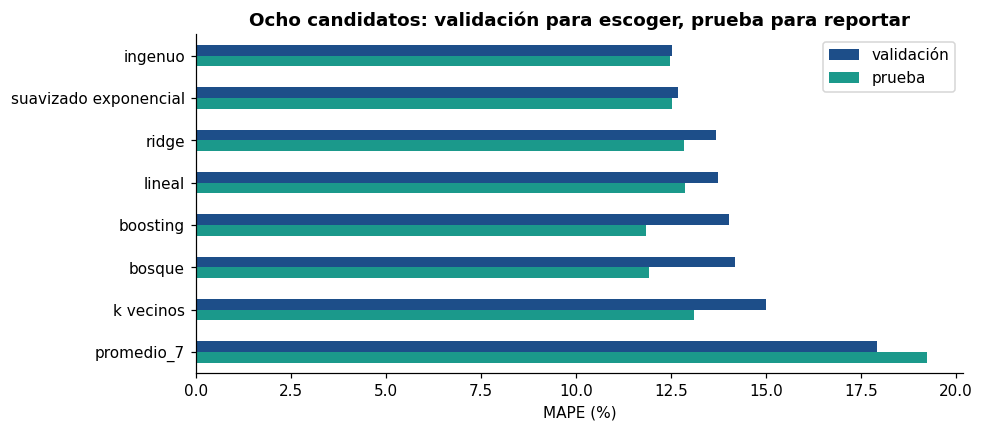

,validación,prueba
ingenuo,12.5,12.5
suavizado exponencial,12.7,12.5
ridge,13.7,12.9
lineal,13.7,12.9
boosting,14.0,11.8
bosque,14.2,11.9
k vecinos,15.0,13.1
promedio_7,17.9,19.2


In [38]:
from taller.luz import competir, pronostico

resultado = competir(datos, H=H,
                     vecinos=5,                       # HUECO 8: cuántos vecinos promedia el modelo; en clase usamos 5
                     fin_validacion="2025-06-30")     # HUECO 9: la fecha en que termina la validación, entre comillas
todos = resultado.errores
print("Días por tramo:", resultado.tramos, "| alfa del suavizado:", resultado.alfa)

todos.sort_values("validación").plot.barh(figsize=(9, 4), color=["#1D4E89", "#1B998B"])
plt.xlabel("MAPE (%)"); plt.title("Ocho candidatos: validación para escoger, prueba para reportar"); plt.gca().invert_yaxis(); plt.show()
display(todos.sort_values("validación").round(1))

**¿Por qué el ganador se escoge en validación y no en prueba?** Respondan en dos líneas, con sus palabras: **Mi respuesta:**

#1.
dado que la prueba se usa para medir finalmente desempeño no para desidir, utilizamos la validacion

Ganador en validación: ingenuo
Su MAPE en prueba: 12.5 %   |   MAPE del ingenuo en prueba: 12.5 %


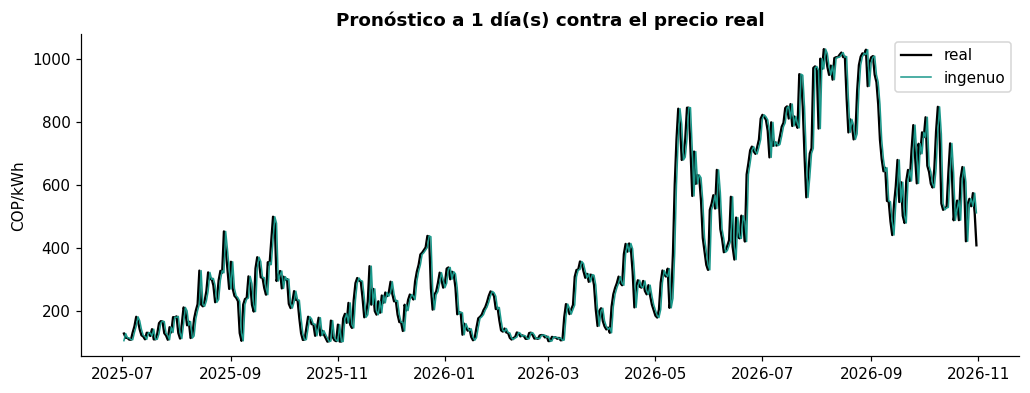

In [39]:
mejor = todos["validación"].idxmin()                          # HUECO 10: la columna con la que se escoge al ganador
resumen = todos["prueba"].round(1)
print(f"Ganador en validación: {mejor}")
print(f"Su MAPE en prueba: {resumen[mejor]} %   |   MAPE del ingenuo en prueba: {resumen['ingenuo']} %")

fechas = resultado.real.index + pd.Timedelta(days=H)
plt.figure(figsize=(11, 3.8))
plt.plot(fechas, resultado.real, color="black", lw=1.5, label="real")
plt.plot(fechas, resultado.pronosticos["ingenuo"], color="#1B998B", lw=1, label="ingenuo")
if mejor != "ingenuo":
    plt.plot(fechas, resultado.pronosticos[mejor], color="#D7263D", lw=1, ls="--", label=mejor)
plt.title(f"Pronóstico a {H} día(s) contra el precio real"); plt.ylabel("COP/kWh"); plt.legend(); plt.show()

### 3.3 Explicar: ¿cuánto del precio se entiende con los embalses?

Dos medidas de asociación. La de Pearson mide relación lineal. La de Spearman mide si una variable sube cuando la otra baja, sin exigir una recta:

$$r=\frac{\sum_t (x_t-\bar x)(y_t-\bar y)}{\sqrt{\sum_t (x_t-\bar x)^2\sum_t (y_t-\bar y)^2}},\qquad r_s=r\ \text{calculado sobre los rangos}.$$

Pearson: -0.16 | Spearman: -0.17


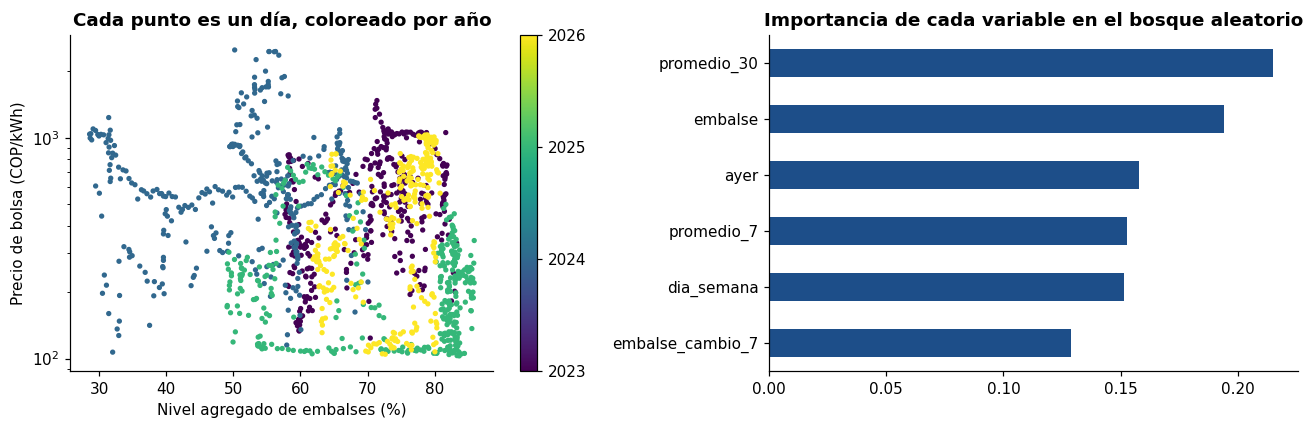

Precio mediano según el nivel de los embalses:
           median  count
embalse                 
(0, 40]     559.0     79
(40, 50]    451.0     62
(50, 60]    436.0    291
(60, 70]    381.0    291
(70, 100]   408.0    677


In [40]:
pearson = datos["precio"].corr(datos["embalse"])               # HUECO 11: la otra variable de la relación
spearman = datos["precio"].corr(datos["embalse"], method="spearman")
print(f"Pearson: {pearson:.2f} | Spearman: {spearman:.2f}")

fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 4))
puntos = izq.scatter(datos["embalse"], datos["precio"], s=6, c=datos.index.year, cmap="viridis")
izq.set(xlabel="Nivel agregado de embalses (%)", ylabel="Precio de bolsa (COP/kWh)", yscale="log", title="Cada punto es un día, coloreado por año")
plt.colorbar(puntos, ax=izq, ticks=sorted(set(datos.index.year)))
resultado.importancias.plot.barh(ax=der, color="#1D4E89")
der.set(title="Importancia de cada variable en el bosque aleatorio"); plt.tight_layout(); plt.show()

por_nivel = datos.groupby(pd.cut(datos["embalse"], [0, 40, 50, 60, 70, 100]), observed=True)["precio"].agg(["median", "count"]).round(0)
print("Precio mediano según el nivel de los embalses:"); print(por_nivel)

Comparen con su tercera apuesta. Luego respondan:

- ¿La relación es una línea recta? ¿Cambia de un año a otro? **Mi lectura:**
- Una correlación no prueba que los embalses causen el precio. ¿Qué otra cosa podría mover las dos variables a la vez? **Mi respuesta:**

#1.
No por que no hay una nube de datos en torno a un camino o nube especifica, hay varias ramificaciones lo que dificulta la explicabilidad y el que una linea recta pueda expresar bien la relacion
#2.
El efecto del cambio climatico o la temporada del año que puede influir con el fenomeno del niño o la niña

## 4. Comunicación

### 4.1 Decidir: ¿desde qué precio fijo conviene firmar?

Con los errores de la prueba armamos una franja alrededor del pronóstico. Sea $c_t=P_{t+h}/\hat P_{t+h}$ el cociente entre lo real y lo pronosticado. La franja que contiene 8 de cada 10 días es

$$\Bigl[\hat P_{T+h}\,\hat Q_{0{,}10}(c),\ \ \hat P_{T+h}\,\hat Q_{0{,}90}(c)\Bigr].$$

Usamos el método más simple entre los que no pierden: si el ganador de validación no mejora al ingenuo en la prueba, nos quedamos con el ingenuo.

In [41]:
elegido = mejor if resumen[mejor] < resumen["ingenuo"] else "ingenuo"
cociente = resultado.real / resultado.pronosticos[elegido]
bajo, alto = cociente.quantile(0.10), cociente.quantile(0.90)      # HUECO 12: el cuantil que deja por debajo 9 de cada 10 días

punto = pronostico(resultado, elegido)
print(f"Horizonte: {H} día(s) | Método elegido: {elegido} (MAPE en prueba {resumen[elegido]} %)")
print(f"Pronóstico para el {(datos.index[-1] + pd.Timedelta(days=H)).date()}: {punto:.0f} COP/kWh")
print(f"Franja de 8 de cada 10 días: entre {punto * bajo:.0f} y {punto * alto:.0f} COP/kWh")
print(f"Ancho de la franja: de {bajo:.2f} a {alto:.2f} veces el pronóstico")

Horizonte: 1 día(s) | Método elegido: ingenuo (MAPE en prueba 12.5 %)
Pronóstico para el 2026-11-01: 408 COP/kWh
Franja de 8 de cada 10 días: entre 334 y 504 COP/kWh
Ancho de la franja: de 0.82 a 1.23 veces el pronóstico


Lean la franja así. Si a la empresa le ofrecen un precio fijo por debajo del borde inferior, casi siempre le conviene firmar. Si se lo ofrecen por encima del borde superior, casi siempre le conviene la bolsa. En el medio, la decisión depende de cuánto le duele un susto.

### La decisión en tres frases

Para el gerente, que no sabe qué es un percentil.

1. **Recomendación:**
2. **Evidencia:**
3. **Riesgo:**

### 4.2 Su post

Como en *El IPC del sancocho*, el resultado se cuenta en láminas. Escriban **su** titular: el hallazgo, no el nombre de la gráfica. Por ejemplo, «Cuando los embalses bajan del 40 %, la luz cuesta el doble», si eso es lo que dicen sus datos. Revisen la tabla de la sección 3.3 antes de escribirlo.

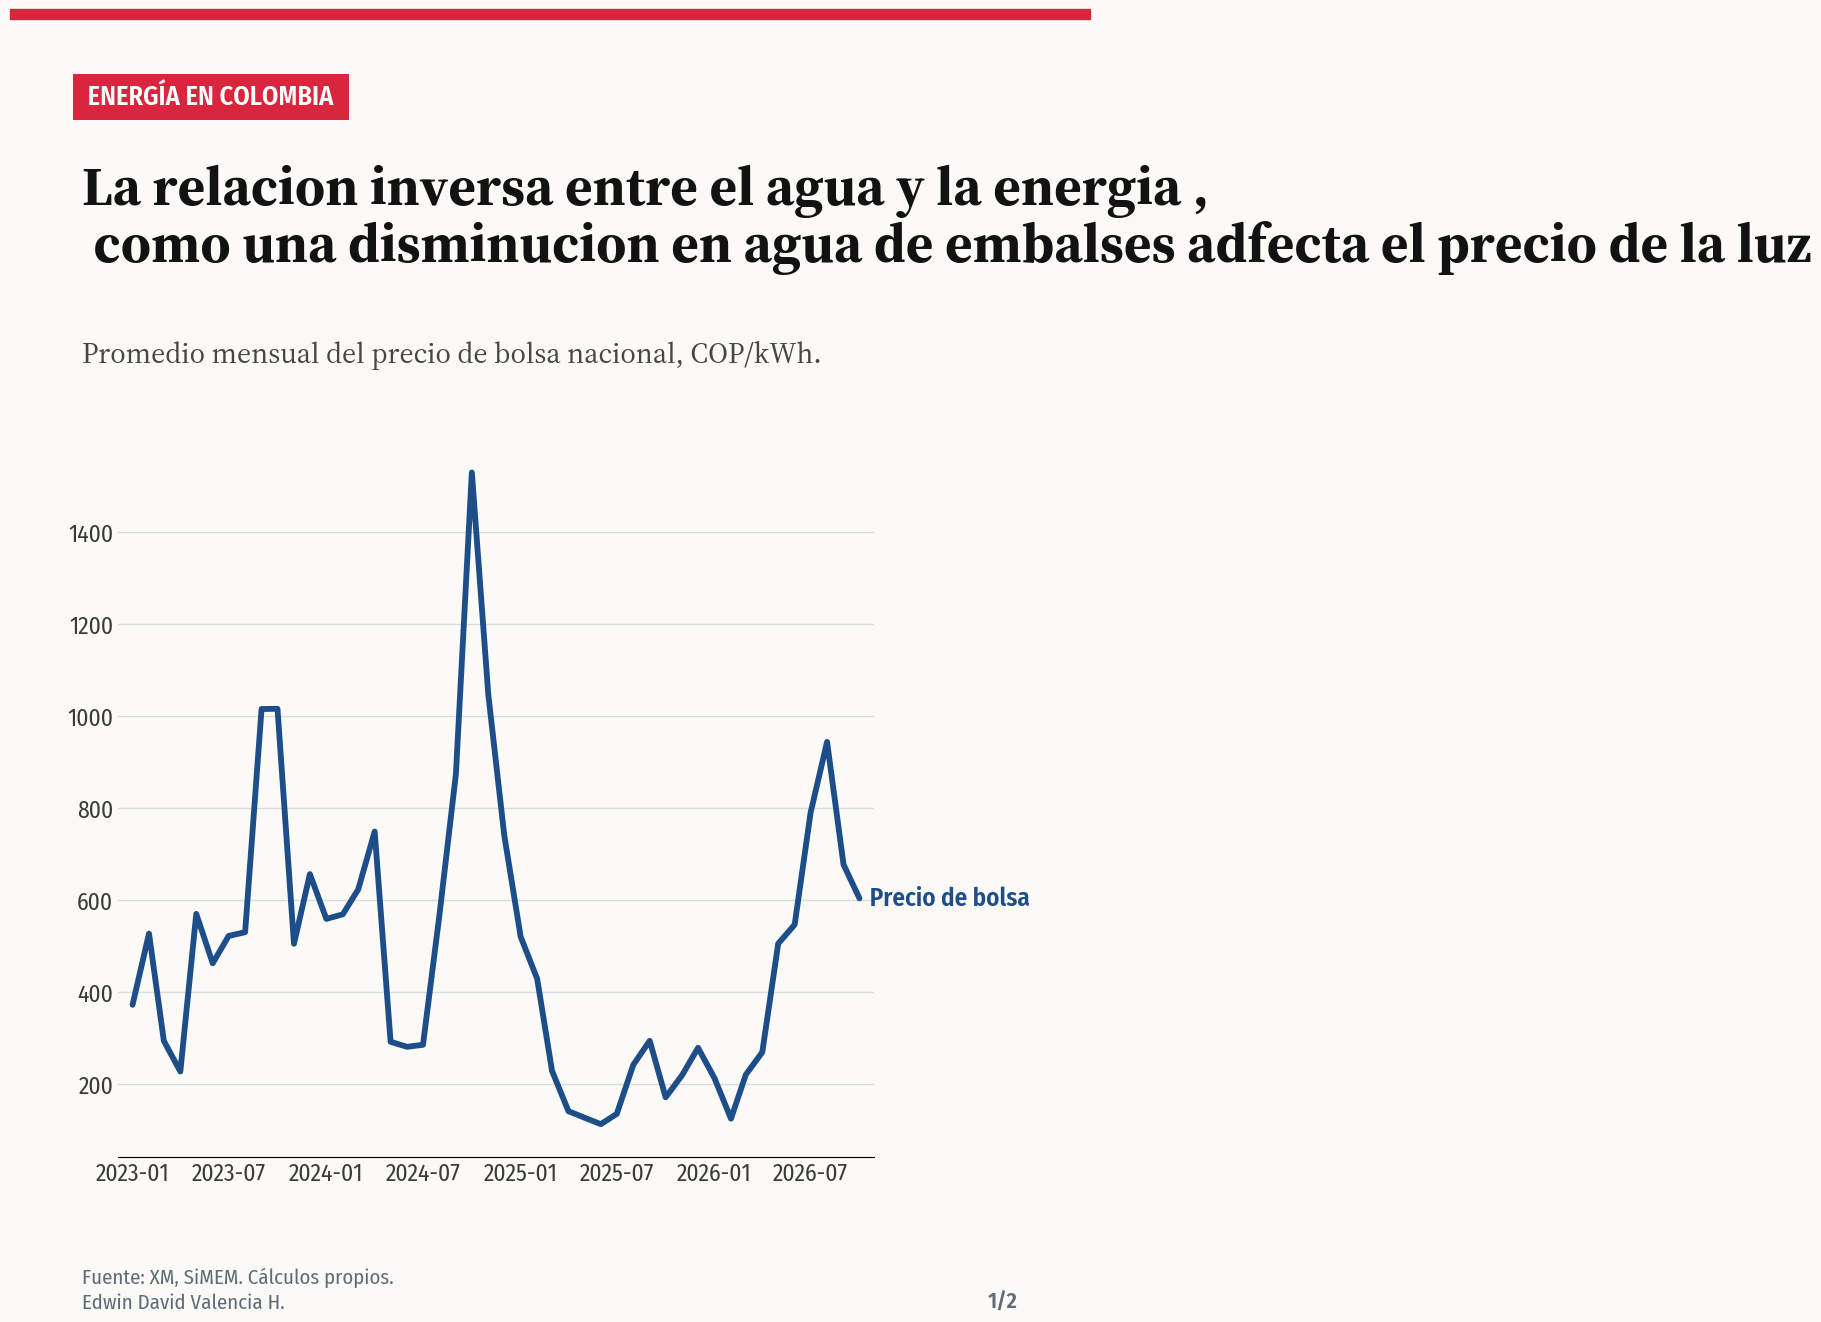

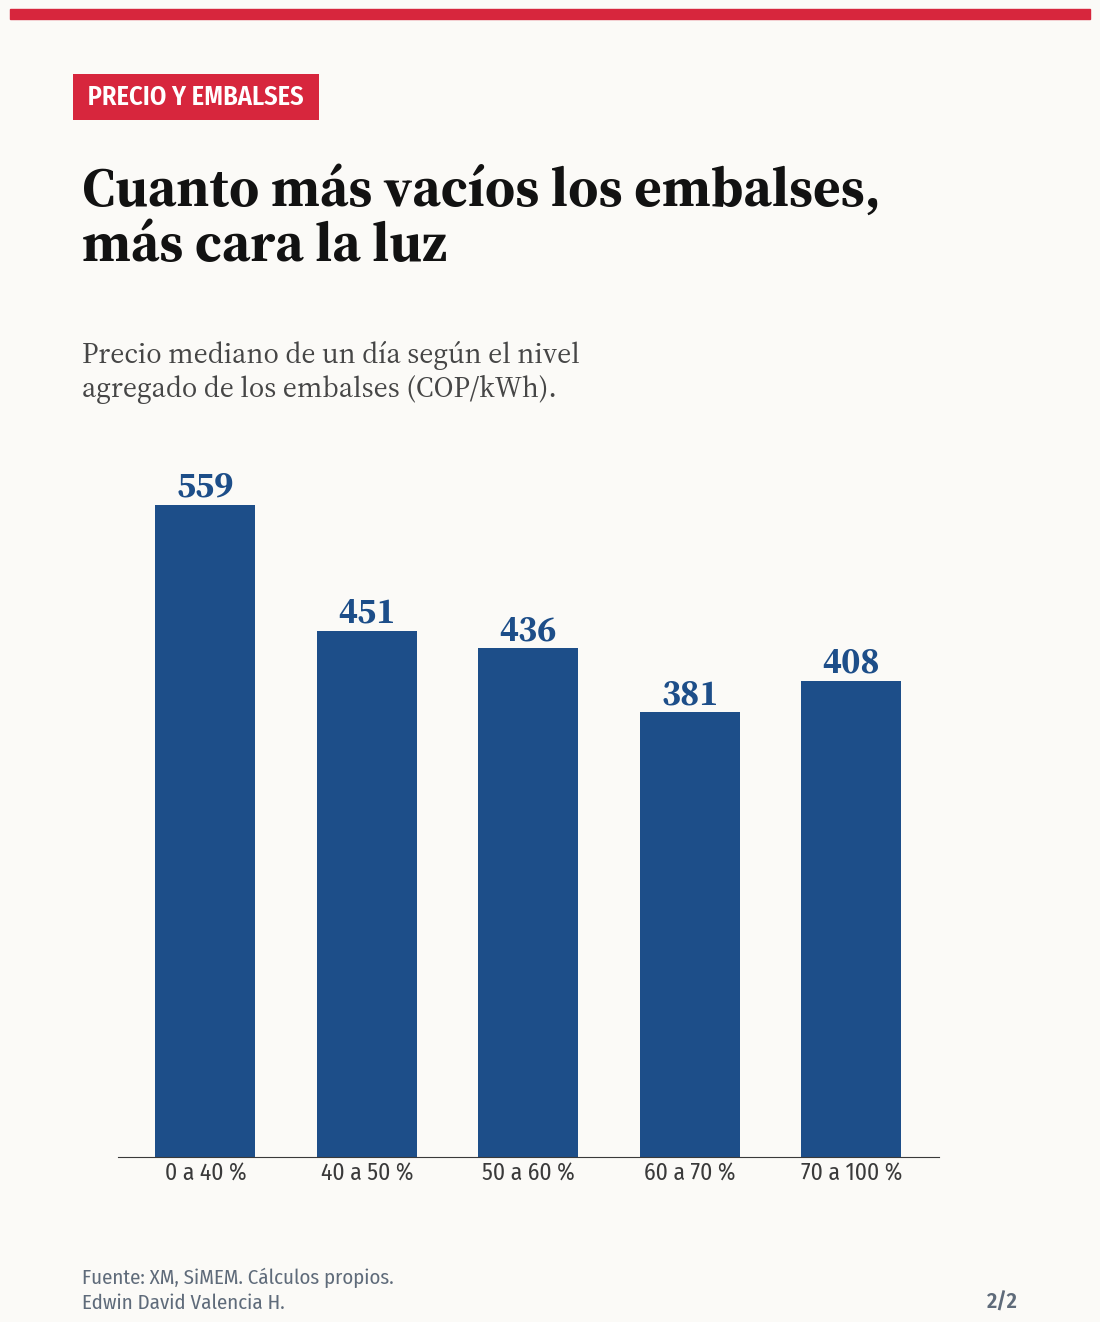

In [42]:
from taller import carrusel as c
c.preparar_fuentes()
PIE = "Fuente: XM, SiMEM. Cálculos propios.\nEdwin David Valencia H."

titular_1 = "La relacion inversa entre el agua y la energia ,\n como una disminucion en agua de embalses adfecta el precio de la luz"              # HUECO 13: su titular, en una o dos líneas (\n parte la línea)
c.lamina_lineas({"Precio de bolsa": datos["precio"].resample("MS").mean()}, {"Precio de bolsa": c.AZUL},
                "ENERGÍA EN COLOMBIA", titular_1, "Promedio mensual del precio de bolsa nacional, COP/kWh.",
                PIE, "1/2", "luz_1.png", base=None)
plt.show()

medianas = {f"{int(i.left)} a {int(i.right)} %": v for i, v in por_nivel["median"].items()}
c.lamina_barras(medianas, {k: c.AZUL for k in medianas}, "PRECIO Y EMBALSES",
                "Cuanto más vacíos los embalses,\nmás cara la luz", "Precio mediano de un día según el nivel\nagregado de los embalses (COP/kWh).",
                PIE, "2/2", "luz_2.png", sufijo="", decimales=0)
plt.show()

Revisen que el titular de la segunda lámina sea cierto con sus datos. Si no lo es, cámbienlo.

### 4.3 Bitácora de decisiones

Llenen las filas vacías. La primera va de ejemplo.

| Decisión | Alternativa descartada | Por qué |
|---|---|---|
| Precio nacional (`PB_Nal`) | `PB_Int`, `PB_Tie` | La empresa compra en el mercado nacional |
| Versión del precio |'TXF' / 'TXI' |abarcamos el total para poner tomar una desicion confiable o en su defecto el promedio de todos asegurando tomar los ultimos datos |
| Filas de embalses que se quitaron |se dejaron todas las filas | solo se manipularon unos emnbalses particulares que se duplicaban en AGREGADO_SIN que contaba 2 veces los 4 que se encuentran en bogota|
| Promedio diario simple | usamos la mediana|se usa un promedio a lo largo ya que es una medida que nos permite ver el valor central para el costo real diario de la luz|
| Tres tramos: entrenamiento, validación y prueba |cross validation | debemos usar series de tiempo ya que par el entrenamiento el orden de los datos importa |
| Pronosticar el cambio relativo y no el nivel |tomar como referencia el valor y pronosticar a partir de ahi |al usar arboles de desicion tienen un funcionamiento diferente por lo que solo pueden trabajar con los datos de entrenamiento|
| Franja con percentiles 10 y 90 |intervalos basados en la desviacion estandar|los percentiles funcionan mejor ya que los errores en este caso no parecen terner distribucion normal |

### 4.4 Riesgos y mantenimiento

- Los días más recientes solo tienen las primeras liquidaciones, que después se corrigen. ¿Qué le pasa a un pronóstico que se hace con datos provisionales?
- ¿Qué le preguntarían a XM sobre las versiones `TXF` y `TXR` antes de usar este análisis con plata de verdad?
- Si llega un fenómeno de El Niño, ¿en cuál de sus tres respuestas confiarían menos?

### 4.5 Cambien una línea

Vuelvan a la celda donde dice `H = 1`, pongan `H = 7` y corran todo de nuevo con *Entorno de ejecución*, *Ejecutar todo*. Llenen la tabla con sus dos corridas.

| | $h=1$ | $h=7$ |
|----|----|----|
| MAPE del ingenuo en prueba |12.5% |27.3%|
| Ganador en validación |ingenuo|Ingenuo|
| MAPE del ganador en prueba |12.5%|27.5%|
| Ancho de la franja |[0.82, 1.23]  |[0.66, 1.61] |

Con la tabla llena, respondan en tres líneas: ¿cuánto le cuesta al gerente, en incertidumbre, cada día adicional de anticipación? ¿Qué le dice eso sobre el precio fijo? **Mi respuesta:**

Dejen el cuaderno entregado con `H = 7` corrido y la tabla completa.

## Para ir más allá: ¿los embalses se llenan y se vacían juntos?

Esta sección es opcional y no tiene nota. Tomo el porcentaje de llenado de cada embalse, lo estandarizo y aplico PCA. Cada punto es un embalse; dos embalses quedan cerca si se llenan y se vacían en las mismas fechas.

In [36]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

llenado = sin_repetir.assign(pct=sin_repetir["VolumenUtilDiarioEnergia"] / sin_repetir["CapacidadUtilEnergia"] * 100)
llenado = llenado[llenado["CapacidadUtilEnergia"] > 0].pivot_table(index="fecha", columns="CodigoEmbalse", values="pct")
llenado = llenado.drop(columns=[c for c in llenado if c.startswith("AGREGADO")]).ffill().dropna()

Zl = StandardScaler().fit_transform(llenado)
pca = PCA(n_components=3).fit(Zl.T)
explicada = pca.explained_variance_ratio_ * 100
puntos = pd.DataFrame(pca.transform(Zl.T), index=llenado.columns, columns=["CP1", "CP2", "CP3"])
region = sin_repetir.drop_duplicates("CodigoEmbalse").set_index("CodigoEmbalse")["RegionHidrologica"].reindex(puntos.index).fillna("sin región")

nube_3d(puntos, grupo=region, etiquetas=True, tamano=7,
        titulo=f"Los {len(puntos)} embalses en tres componentes",
        subtitulo="Cada punto es un embalse. Arrastren para girar.",
        ejes=[f"CP{j + 1} ({explicada[j]:.0f} %)" for j in range(3)]).show()
print(f"{llenado.shape[1]} embalses | Los tres primeros componentes explican {explicada.sum():.0f} % de la varianza")

23 embalses | Los tres primeros componentes explican 48 % de la varianza


### Procedencia y entrega

In [ ]:
procedencia()

**Para entregar:** en Colab, menú *Archivo*, *Guardar una copia en GitHub*, y escojan su repositorio de portafolio, carpeta `clase01/`. Suban también sus dos láminas (`luz_1.png` y `luz_2.png`, en el panel de archivos de Colab). Un cuaderno que no corre de principio a fin desde cero no se califica: antes de guardar usen *Entorno de ejecución*, *Reiniciar sesión y ejecutar todo*.